# Phenotype Clustering: LSTM vs MOMENT

Generates window-level embeddings from both trained encoders, clusters each with K-means (silhouette-selected k, following Hilders), and compares the resulting phenotypes.

Clustering is per-window, not per-patient - matches Hilders' `generate_encodings`, and is what lets a patient's phenotype shift over their stay.


## Imports

In [1]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm
from functools import partial

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')


Using device: cuda


In [2]:
from pathlib import Path
print(Path('model_checkpoints/full_baseline/SGROUPmodel_mortality_best.pth').exists())
print(Path('model_checkpoints/moment_baseline/SGROUPmodel_moment_best.pth').exists())
print(Path('data/moment_cache/val_embeddings.pt').exists())

True
True
True


## Config



In [ ]:
FEATURES_INCLUDED = [
    'ast', 'alt', 'bicarbonate', 'bilirubin', 'bun', 'calcium', 'chloride',
    'potassium', 'creatinine', 'glucose', 'heart_rate', 'hematocrit', 'hemoglobin',
    'lactate', 'spo2', 'pao2', 'paco2', 'ph', 'platelet', 'resp_rate',
    'sodium', 'sysbp', 'meanbp', 'diasbp', 'tempc', 'wbc', 'gcs_eye',
    'gcs_motor', 'admission_age_norm', 'weight_norm', 'height_norm',
    'weight_null', 'height_null', 'gender'
]

OUTCOMES_INCLUDED = [
    '90day_mortality',
    'LOS_remaining_days',
    'rrt_next_timestep',
    'mv_next_timestep'
]

UNIQUE_STAY_ID = 'admissionid'
EMBEDDING_SIZE = 32

MOMENT_MODEL_NAME = 'AutonLab/MOMENT-1-base'
CONTEXT_LENGTH = 512
PATCH_LENGTH = 8
CACHE_DIR = Path('data/moment_cache')

LSTM_CHECKPOINT = Path('model_checkpoints/full_baseline/SGROUPmodel_mortality_best.pth')
MOMENT_CHECKPOINT = Path('model_checkpoints/moment_baseline/SGROUPmodel_moment_best.pth')

assert LSTM_CHECKPOINT.exists(), f'{LSTM_CHECKPOINT} not found'
assert MOMENT_CHECKPOINT.exists(), f'{MOMENT_CHECKPOINT} not found'
print('Both checkpoints found.')


Both checkpoints found.


## Model classes

Same as notebooks 06/07 - rebuild both architectures and load their weights. From Hilders' public code.

In [4]:
class ICUDataset(Dataset):
    def __init__(self, data, features, outcomes, unique_stay_id='admissionid'):
        self.data = data
        self.vo_ids = data[unique_stay_id].unique()
        self.features = features
        self.outcomes = outcomes
        self.unique_stay_id = unique_stay_id

    def __len__(self):
        return len(self.vo_ids)

    def __getitem__(self, idx):
        visit_id = self.vo_ids[idx]
        patient_data = self.data[self.data[self.unique_stay_id] == visit_id]
        sequence = patient_data[self.features].values
        labels = patient_data[self.outcomes].values
        return torch.tensor(sequence, dtype=torch.float32), torch.tensor(labels, dtype=torch.float32)


def custom_collate_fn(batch):
    X, y = list(zip(*batch))
    return X, y


class LSTM_Encoder(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_layers=3, device='cpu'):
        super().__init__()
        self.device = device
        self.lstm = nn.LSTM(input_size=input_dim, hidden_size=hidden_dim, num_layers=num_layers, batch_first=True).to(self.device)

    def forward(self, input, input_padded=False):
        from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence
        input_lens = list(map(len, input))
        if not input_padded:
            input = pad_sequence(input, batch_first=True)
        input_packed = pack_padded_sequence(input, input_lens, batch_first=True, enforce_sorted=False).to(self.device)
        encoded, (ht, ct) = self.lstm(input_packed)
        output, output_lens = pad_packed_sequence(encoded, batch_first=True)
        return encoded, output, output_lens


class ExponentialActivation(nn.Module):
    def forward(self, input):
        return torch.exp(input)


ACTIVATION_DICT = {'sigmoid': nn.Sigmoid(), 'exp': ExponentialActivation()}


class MLP_Predictor(nn.Module):
    def __init__(self, encoder_dim, output_dim, output_activation=None, device='cpu'):
        super().__init__()
        self.device = device
        intermediate_dim = encoder_dim // 2
        layers = [nn.Linear(encoder_dim, intermediate_dim), nn.BatchNorm1d(intermediate_dim), nn.ReLU(), nn.Linear(intermediate_dim, output_dim)]
        if output_activation is not None:
            layers.append(ACTIVATION_DICT[output_activation])
        self.network = nn.Sequential(*layers).to(self.device)

    def forward(self, input):
        input = input.to(self.device)
        batch_size, seq_len, feature_dim = input.shape
        input = input.view(-1, feature_dim)
        output = self.network(input)
        return output.view(batch_size, seq_len, -1)


class SGROUP_Network(nn.Module):
    ALL_CRITERIA = {
        'mortality': {'criterion': nn.BCEWithLogitsLoss(reduction='none'), 'weight': 1.0, 'is_binary': True, 'output_config': (1, None)},
        'LOS': {'criterion': nn.MSELoss(reduction='none'), 'weight': 0.001, 'is_binary': False, 'output_config': (1, 'exp')},
        'rrt': {'criterion': nn.BCEWithLogitsLoss(reduction='none'), 'weight': 0.25, 'is_binary': True, 'output_config': (1, None)},
        'mv': {'criterion': nn.BCEWithLogitsLoss(reduction='none'), 'weight': 0.25, 'is_binary': True, 'output_config': (1, None)}
    }

    def __init__(self, input_dim, hidden_dim, outcomes=['mortality'], encoder_class=None,
                 predictor_class=MLP_Predictor, num_encoder_layers=3, device='cpu'):
        super().__init__()
        self.device = device
        self.outcomes = outcomes
        self.encoder = encoder_class(input_dim, hidden_dim, num_layers=num_encoder_layers, device=self.device)
        self.criteria = {key: self.ALL_CRITERIA[key] for key in outcomes}
        self.predictors = nn.ModuleList([
            predictor_class(hidden_dim, self.criteria[key]['output_config'][0],
                             output_activation=self.criteria[key]['output_config'][1], device=self.device)
            for key in outcomes
        ])

    def forward(self, input):
        encoding, output, output_lens = self.encoder(input)
        predictions = [predictor(output) for predictor in self.predictors]
        return encoding, output, output_lens, predictions


class CachedMOMENT_Encoder(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_layers=None, device='cpu', moment_dim=None, patch_length=PATCH_LENGTH):
        super().__init__()
        self.device = device
        self.patch_length = patch_length
        if moment_dim is None:
            raise ValueError('moment_dim must be provided')
        self.projection = nn.Linear(moment_dim, hidden_dim).to(self.device)

    def forward(self, input, input_padded=False):
        embeddings_batch, orig_lens_batch = input
        embeddings_batch = embeddings_batch.to(self.device)
        projected = self.projection(embeddings_batch)
        output = projected.repeat_interleave(self.patch_length, dim=1)
        return output, output, orig_lens_batch


class CachedEmbeddingDataset(Dataset):
    def __init__(self, cache_path, raw_data, outcomes, unique_stay_id='admissionid'):
        cache = torch.load(cache_path, weights_only=False)
        self.admission_ids = cache['admission_ids']
        self.embeddings = cache['embeddings']
        self.orig_lens = cache['orig_lens']
        self.moment_dim = cache['moment_dim']
        self.raw_data = raw_data
        self.outcomes = outcomes
        self.unique_stay_id = unique_stay_id

    def __len__(self):
        return len(self.admission_ids)

    def __getitem__(self, idx):
        admission_id = self.admission_ids[idx]
        embedding = self.embeddings[idx]
        orig_len = int(self.orig_lens[idx].item())
        patient_data = self.raw_data[self.raw_data[self.unique_stay_id] == admission_id]
        labels = torch.tensor(patient_data[self.outcomes].values, dtype=torch.float32)
        return embedding, orig_len, labels


def cached_collate_fn(batch):
    embeddings, orig_lens, labels = zip(*batch)
    embeddings_batch = torch.stack(embeddings)
    orig_lens_batch = torch.tensor(orig_lens)
    return (embeddings_batch, orig_lens_batch), list(labels)


## Load validation data



In [5]:
val_data = pd.read_csv('../data/splits/val.csv')
val_data = val_data.sort_values(['admissionid', 'window']).reset_index(drop=True)
val_data['window_rank'] = val_data.groupby('admissionid').cumcount()

print(f'{val_data.shape}, {val_data.admissionid.nunique()} admissions, {len(val_data)} total windows')
val_data[['admissionid', 'window', 'window_rank']].head(10)


(23890, 47), 397 admissions, 23890 total windows


,admissionid,window,window_rank
0,160.0,0,0
1,160.0,1,1
2,160.0,2,2
3,160.0,3,3
4,160.0,4,4
5,160.0,5,5
6,160.0,6,6
7,160.0,7,7
8,160.0,8,8
9,160.0,9,9


## Generate window-level encodings

From Hilders' generate_encodings(). 

In [6]:
def generate_window_level_encodings(model, dataloader, admission_order, device):
    """admission_order: dataset's ID list, in the exact order the (shuffle=False) dataloader iterates."""
    model.eval()
    records = []
    idx_pointer = 0

    with torch.no_grad():
        for X, y in tqdm(dataloader, desc='Generating encodings'):
            encoding, output, output_lens, predictions = model(X)
            batch_size = output.shape[0]

            for i in range(batch_size):
                admission_id = admission_order[idx_pointer]
                length = int(output_lens[i])
                for j in range(length):
                    records.append({
                        'admissionid': admission_id,
                        'window_rank': j,
                        'embedding': output[i, j].cpu().numpy()
                    })
                idx_pointer += 1

    return pd.DataFrame(records)


## LSTM encodings

Claude AI. Prompt- Need to run the generate encodings on both LSTM and MOMENT models 

In [7]:
lstm_model = SGROUP_Network(
    input_dim=len(FEATURES_INCLUDED),
    hidden_dim=EMBEDDING_SIZE,
    outcomes=['mortality', 'LOS', 'rrt', 'mv'],
    encoder_class=LSTM_Encoder,
    device=device
).to(device)
lstm_model.load_state_dict(torch.load(LSTM_CHECKPOINT, weights_only=True, map_location=device))

lstm_val_dataset = ICUDataset(val_data, FEATURES_INCLUDED, OUTCOMES_INCLUDED, unique_stay_id=UNIQUE_STAY_ID)
lstm_val_dataloader = DataLoader(lstm_val_dataset, batch_size=256, shuffle=False, collate_fn=custom_collate_fn)

lstm_encodings = generate_window_level_encodings(lstm_model, lstm_val_dataloader, list(lstm_val_dataset.vo_ids), device)
print(f'{len(lstm_encodings)} LSTM window-level encodings generated')
lstm_encodings.head()


Generating encodings:   0%|          | 0/2 [00:00<?, ?it/s]

23890 LSTM window-level encodings generated


,admissionid,window_rank,embedding
0,160.0,0,"[-0.07965343, -0.042822793, 0.08370405, -0.038..."
1,160.0,1,"[-0.046471894, -0.044302102, 0.18310058, -0.03..."
2,160.0,2,"[-0.0077804807, -0.026876822, 0.26816097, -0.0..."
3,160.0,3,"[0.019865043, -0.007940635, 0.33780766, -0.033..."
4,160.0,4,"[0.03760718, 0.004744646, 0.38950053, -0.04187..."


## MOMENT encodings



In [8]:
_cache = torch.load(CACHE_DIR / 'val_embeddings.pt', weights_only=False)
MOMENT_DIM = _cache['moment_dim']

moment_model = SGROUP_Network(
    input_dim=len(FEATURES_INCLUDED),
    hidden_dim=EMBEDDING_SIZE,
    outcomes=['mortality', 'LOS', 'rrt', 'mv'],
    encoder_class=partial(CachedMOMENT_Encoder, moment_dim=MOMENT_DIM),
    device=device
).to(device)
moment_model.load_state_dict(torch.load(MOMENT_CHECKPOINT, weights_only=True, map_location=device))

moment_val_dataset = CachedEmbeddingDataset(CACHE_DIR / 'val_embeddings.pt', val_data, OUTCOMES_INCLUDED, unique_stay_id=UNIQUE_STAY_ID)
moment_val_dataloader = DataLoader(moment_val_dataset, batch_size=256, shuffle=False, collate_fn=cached_collate_fn)

moment_encodings = generate_window_level_encodings(moment_model, moment_val_dataloader, list(moment_val_dataset.admission_ids), device)
print(f'{len(moment_encodings)} MOMENT window-level encodings generated')
moment_encodings.head()


Generating encodings:   0%|          | 0/2 [00:00<?, ?it/s]

23844 MOMENT window-level encodings generated


,admissionid,window_rank,embedding
0,160.0,0,"[-0.045125887, 0.2992778, 0.12840636, 0.396800..."
1,160.0,1,"[-0.045125887, 0.2992778, 0.12840636, 0.396800..."
2,160.0,2,"[-0.045125887, 0.2992778, 0.12840636, 0.396800..."
3,160.0,3,"[-0.045125887, 0.2992778, 0.12840636, 0.396800..."
4,160.0,4,"[-0.045125887, 0.2992778, 0.12840636, 0.396800..."


## Join encodings back to features

Claude AI. Prompt- join the embeddings back to the original data on patient id and window. make sure nothing got mismatched

In [9]:
lstm_full = lstm_encodings.merge(val_data, on=['admissionid', 'window_rank'], how='left', validate='one_to_one')
moment_full = moment_encodings.merge(val_data, on=['admissionid', 'window_rank'], how='left', validate='one_to_one')

assert lstm_full[FEATURES_INCLUDED[0]].notna().all(), 'unmatched rows after LSTM merge'
assert moment_full[FEATURES_INCLUDED[0]].notna().all(), 'unmatched rows after MOMENT merge'
print('Merge validated.')
print(f'LSTM: {len(lstm_full)} rows, MOMENT: {len(moment_full)} rows')


Merge validated.
LSTM: 23890 rows, MOMENT: 23844 rows


## Silhouette analysis - choose k for each encoder

Follows Hilders' approach. `SILHOUETTE_SAMPLE_SIZE` subsamples for the silhouette score.

In [10]:
SEED = 42
CANDIDATE_K = [3, 4, 5, 6, 7, 8, 9, 10]
SILHOUETTE_SAMPLE_SIZE = 5000


def silhouette_analysis(embeddings, candidate_k, seed, sample_size=None, label=''):
    scores = []
    for k in tqdm(candidate_k, desc=f'Silhouette analysis ({label})'):
        clusterer = KMeans(n_clusters=k, random_state=seed, n_init=10, max_iter=5000, init='random').fit(embeddings)
        labels = clusterer.labels_
        score = silhouette_score(embeddings, labels, sample_size=sample_size, random_state=seed)
        scores.append(score)
        print(f'  k={k}: silhouette={score:.4f}')
    best_k = candidate_k[int(np.argmax(scores))]
    return best_k, scores


lstm_embeddings_arr = np.stack(lstm_full['embedding'].values)
moment_embeddings_arr = np.stack(moment_full['embedding'].values)

print('LSTM:')
lstm_best_k, lstm_scores = silhouette_analysis(lstm_embeddings_arr, CANDIDATE_K, SEED, SILHOUETTE_SAMPLE_SIZE, label='LSTM')
print(f'Best k for LSTM: {lstm_best_k}\n')

print('MOMENT:')
moment_best_k, moment_scores = silhouette_analysis(moment_embeddings_arr, CANDIDATE_K, SEED, SILHOUETTE_SAMPLE_SIZE, label='MOMENT')
print(f'Best k for MOMENT: {moment_best_k}')


LSTM:


Silhouette analysis (LSTM):   0%|          | 0/8 [00:00<?, ?it/s]

  k=3: silhouette=0.2863
  k=4: silhouette=0.2985
  k=5: silhouette=0.2702
  k=6: silhouette=0.2901
  k=7: silhouette=0.2887
  k=8: silhouette=0.2976
  k=9: silhouette=0.2880
  k=10: silhouette=0.2926
Best k for LSTM: 4

MOMENT:


Silhouette analysis (MOMENT):   0%|          | 0/8 [00:00<?, ?it/s]

  k=3: silhouette=0.1808
  k=4: silhouette=0.1717
  k=5: silhouette=0.1527
  k=6: silhouette=0.1421
  k=7: silhouette=0.1567
  k=8: silhouette=0.1413
  k=9: silhouette=0.1409
  k=10: silhouette=0.1412
Best k for MOMENT: 3


Claude AI. Prompt- plot both silhouette curves on the same chart

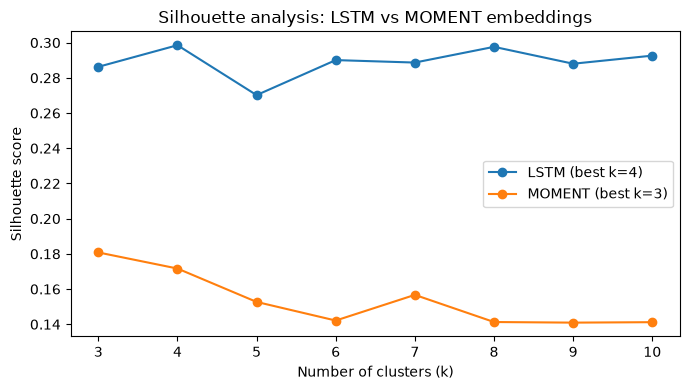

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(CANDIDATE_K, lstm_scores, marker='o', label=f'LSTM (best k={lstm_best_k})')
ax.plot(CANDIDATE_K, moment_scores, marker='o', label=f'MOMENT (best k={moment_best_k})')
ax.set_xlabel('Number of clusters (k)')
ax.set_ylabel('Silhouette score')
ax.set_title('Silhouette analysis: LSTM vs MOMENT embeddings')
ax.legend()
plt.tight_layout()
plt.show()


## Fit final clusterers

From Hilders' fit_clustering_algorithm()

In [12]:
lstm_clusterer = KMeans(n_clusters=lstm_best_k, random_state=SEED, n_init=10, max_iter=5000, init='random').fit(lstm_embeddings_arr)
lstm_full['cluster_id'] = lstm_clusterer.labels_

moment_clusterer = KMeans(n_clusters=moment_best_k, random_state=SEED, n_init=10, max_iter=5000, init='random').fit(moment_embeddings_arr)
moment_full['cluster_id'] = moment_clusterer.labels_

print('LSTM cluster sizes:')
print(lstm_full['cluster_id'].value_counts().sort_index())
print('\nMOMENT cluster sizes:')
print(moment_full['cluster_id'].value_counts().sort_index())


LSTM cluster sizes:
cluster_id
0    9283
1    7011
2    2690
3    4906
Name: count, dtype: int64

MOMENT cluster sizes:
cluster_id
0    10483
1     9360
2     4001
Name: count, dtype: int64


## Cluster profiles

From Hilders' display_cluster_stats.py table. Modified using Claude AI. Prompt- Here is hilders' cluster stats script, need a similar function for a summary table

In [13]:
NON_NORMAL_VARS = ['bun', 'creatinine', 'glucose', 'spo2', 'pao2', 'paco2', 'ph', 'platelet', 'wbc', 'LOS_remaining_days']
BINARY_VARS = ['90day_mortality', 'gender', 'rrt_next_timestep', 'mv_next_timestep', 'weight_null', 'height_null']


def cluster_profile_table(df, features, outcomes, n_clusters):
    rows = []
    for col in features + outcomes:
        row = {'variable': col}
        for c in range(n_clusters):
            cluster_data = df[df['cluster_id'] == c][col]
            if col in BINARY_VARS:
                pct = cluster_data.mean() * 100
                row[f'cluster_{c}'] = f'{pct:.1f}%'
            elif col in NON_NORMAL_VARS:
                median, q1, q3 = cluster_data.median(), cluster_data.quantile(0.25), cluster_data.quantile(0.75)
                row[f'cluster_{c}'] = f'{median:.1f} [{q1:.1f}, {q3:.1f}]'
            else:
                mean, std = cluster_data.mean(), cluster_data.std()
                row[f'cluster_{c}'] = f'{mean:.1f} (±{std:.1f})'
        rows.append(row)

    sizes = df['cluster_id'].value_counts().sort_index()
    size_row = {'variable': 'N (%)'}
    for c in range(n_clusters):
        size_row[f'cluster_{c}'] = f'{sizes.get(c, 0)} ({sizes.get(c, 0) / len(df) * 100:.1f}%)'

    return pd.DataFrame([size_row] + rows).set_index('variable')


print('LSTM cluster profiles:')
lstm_profile = cluster_profile_table(lstm_full, FEATURES_INCLUDED, OUTCOMES_INCLUDED, lstm_best_k)
lstm_profile


LSTM cluster profiles:


,cluster_0,cluster_1,cluster_2,cluster_3
variable,,,,
N (%),9283 (38.9%),7011 (29.3%),2690 (11.3%),4906 (20.5%)
ast,55.7 (±81.8),44.5 (±27.4),382.4 (±1197.6),67.5 (±92.1)
alt,70.0 (±183.7),56.2 (±78.5),230.0 (±656.3),55.1 (±66.6)
bicarbonate,27.9 (±4.6),27.2 (±4.0),22.9 (±5.5),23.3 (±5.4)
bilirubin,19.5 (±44.3),10.5 (±13.0),38.6 (±80.1),16.2 (±32.3)
bun,"11.6 [11.6, 11.6]","11.6 [7.9, 11.6]","16.8 [11.6, 29.1]","11.6 [7.8, 12.3]"
calcium,2.0 (±0.2),2.0 (±0.2),2.0 (±0.2),1.9 (±0.2)
chloride,106.9 (±4.8),106.9 (±4.4),107.4 (±5.4),108.5 (±5.7)
potassium,4.1 (±0.4),4.1 (±0.4),4.3 (±0.6),4.1 (±0.5)


In [14]:
print('MOMENT cluster profiles:')
moment_profile = cluster_profile_table(moment_full, FEATURES_INCLUDED, OUTCOMES_INCLUDED, moment_best_k)
moment_profile


MOMENT cluster profiles:


,cluster_0,cluster_1,cluster_2
variable,,,
N (%),10483 (44.0%),9360 (39.3%),4001 (16.8%)
ast,52.4 (±86.3),112.7 (±532.7),145.7 (±603.7)
alt,54.1 (±58.3),102.8 (±348.6),100.2 (±323.4)
bicarbonate,27.4 (±4.6),25.8 (±5.3),23.8 (±5.5)
bilirubin,15.4 (±27.9),22.5 (±57.3),16.2 (±32.3)
bun,"11.6 [11.6, 11.6]","11.6 [10.1, 11.6]","11.6 [8.1, 12.7]"
calcium,2.0 (±0.2),2.0 (±0.2),2.0 (±0.2)
chloride,106.7 (±5.0),107.8 (±5.0),107.7 (±5.1)
potassium,4.1 (±0.4),4.1 (±0.4),4.1 (±0.5)


## Encoders ARI 

Adjusted Rand Index on matched windows. ARI=1 identical, ARI~0 no better than chance.  
Claude AI. Prompt- How do I check the similarity and difference between both clusterings? Need to run that on the model clusters and see the clustering plots.

In [15]:
agreement_df = lstm_full[['admissionid', 'window_rank', 'cluster_id']].rename(columns={'cluster_id': 'lstm_cluster'}).merge(
    moment_full[['admissionid', 'window_rank', 'cluster_id']].rename(columns={'cluster_id': 'moment_cluster'}),
    on=['admissionid', 'window_rank'], how='inner'
)

ari = adjusted_rand_score(agreement_df['lstm_cluster'], agreement_df['moment_cluster'])
print(f'Adjusted Rand Index (LSTM vs MOMENT clusters): {ari:.4f}')
print(f'({len(agreement_df)} matched windows compared)')

contingency = pd.crosstab(agreement_df['lstm_cluster'], agreement_df['moment_cluster'], normalize='index')
print('\nRow-normalised contingency table:')
contingency


Adjusted Rand Index (LSTM vs MOMENT clusters): 0.0987
(23844 matched windows compared)

Row-normalised contingency table:


moment_cluster,0,1,2
lstm_cluster,,,
0,0.667460,0.289471,0.043069
1,0.334760,0.457709,0.207531
2,0.374535,0.412509,0.212956
3,0.196086,0.482674,0.321239


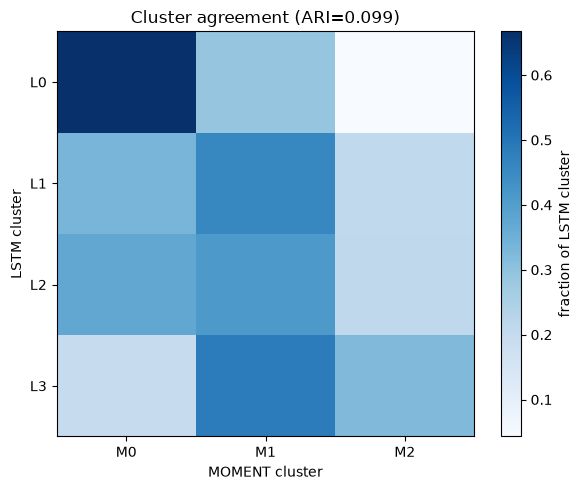

In [16]:
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(contingency.values, cmap='Blues', aspect='auto')
ax.set_xticks(range(len(contingency.columns)))
ax.set_xticklabels([f'M{c}' for c in contingency.columns])
ax.set_yticks(range(len(contingency.index)))
ax.set_yticklabels([f'L{c}' for c in contingency.index])
ax.set_xlabel('MOMENT cluster')
ax.set_ylabel('LSTM cluster')
ax.set_title(f'Cluster agreement (ARI={ari:.3f})')
plt.colorbar(im, label='fraction of LSTM cluster')
plt.tight_layout()
plt.show()


## PCA projection 


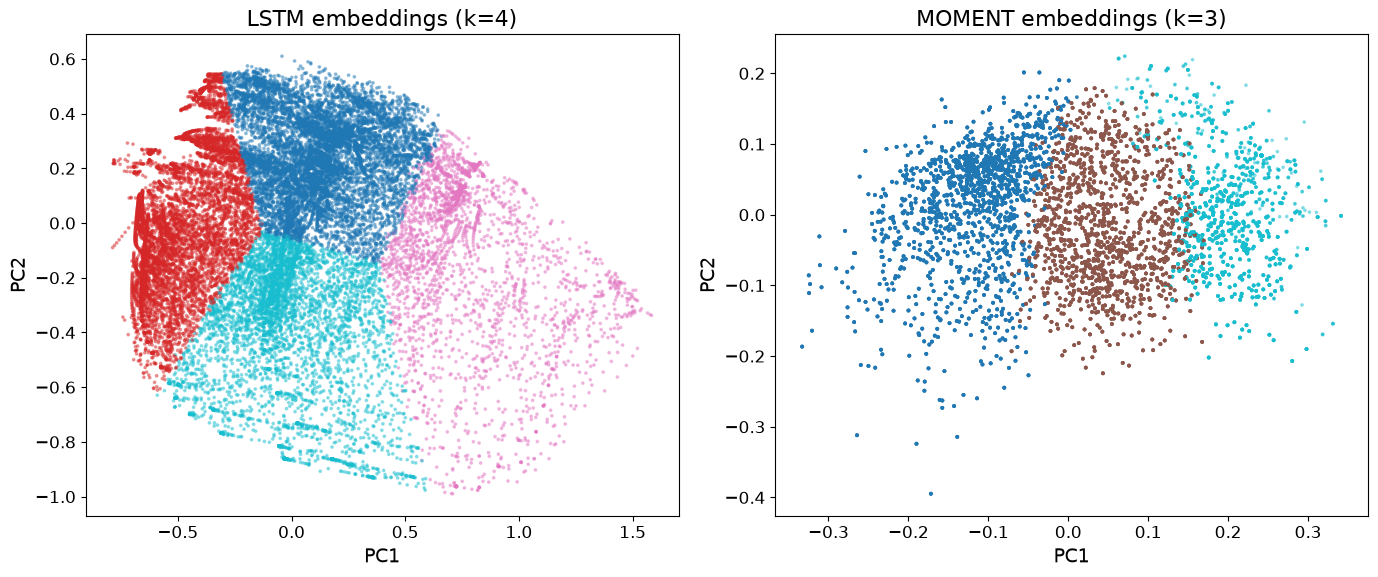

<Figure size 640x480 with 0 Axes>

In [19]:
import matplotlib as mpl
mpl.rcParams.update({
    'font.size': 14,
    'axes.titlesize': 16,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 12,
})

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

lstm_pca = PCA(n_components=2, random_state=SEED).fit_transform(lstm_embeddings_arr)
axes[0].scatter(lstm_pca[:, 0], lstm_pca[:, 1], c=lstm_full['cluster_id'], cmap='tab10', s=3, alpha=0.4)
axes[0].set_title(f'LSTM embeddings (k={lstm_best_k})')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')

moment_pca = PCA(n_components=2, random_state=SEED).fit_transform(moment_embeddings_arr)
axes[1].scatter(moment_pca[:, 0], moment_pca[:, 1], c=moment_full['cluster_id'], cmap='tab10', s=3, alpha=0.4)
axes[1].set_title(f'MOMENT embeddings (k={moment_best_k})')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')

plt.tight_layout()
plt.show()

plt.savefig('cluster_embeddings.png', dpi=200, bbox_inches='tight')

## Save results

In [18]:
RESULTS_DIR = Path('../results/clustering')
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

lstm_full.drop(columns=['embedding']).to_csv(RESULTS_DIR / 'lstm_clusters.csv', index=False)
moment_full.drop(columns=['embedding']).to_csv(RESULTS_DIR / 'moment_clusters.csv', index=False)
lstm_profile.to_csv(RESULTS_DIR / 'lstm_cluster_profile.csv')
moment_profile.to_csv(RESULTS_DIR / 'moment_cluster_profile.csv')

print(f'Saved to {RESULTS_DIR}/')


Saved to ..\results\clustering/
